# 01 · Rules, Not Code

**The paradigm shift.** When handed an assignment problem, the instinct is to *write a solver*: loop over people, greedily grab the first free task, then patch the cases where that gets stuck. Constraint programming replaces all of it with a *declaration of the rules* — variables plus constraints — handed to a search.

Here is a tiny staff-assignment problem solved both ways: the greedy scheduler gets stuck, while the declared-rules version finds a valid assignment instantly.

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether the notebook runs from repo root or notebooks/.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

%matplotlib inline
import matplotlib.pyplot as plt

from src.persistence import save_figure, save_json

print("figures ->", save_figure.__module__, "| ready")

figures -> src.persistence | ready


## The problem
Four people, four tasks. `qualified[p][t] == 1` means person *p* can do task *t*. We need a one-to-one assignment (everyone a task, every task covered).

In [2]:
people = ["Ava", "Ben", "Cara", "Dan"]
tasks = ["Triage", "Lab", "Reception", "Pharmacy"]
# Deliberately laid out so a naive greedy pass paints itself into a corner.
qualified = [
    [1, 1, 0, 0],  # Ava:  Triage, Lab
    [1, 0, 0, 0],  # Ben:  Triage only
    [0, 0, 1, 1],  # Cara: Reception, Pharmacy
    [0, 0, 1, 0],  # Dan:  Reception only
]
save_json("01_assignment_input", {"people": people, "tasks": tasks, "qualified": qualified})

PosixPath('/workspaces/constraint_programming_101/outputs/data/01_assignment_input.json')

## The hand-coded way: greedy, and it gets stuck
Assign each person the first task they are qualified for that is still free.

In [3]:
def greedy_assign(qualified):
    n = len(qualified)
    assigned = [-1] * n
    taken = set()
    for p in range(n):
        for t in range(n):
            if qualified[p][t] and t not in taken:
                assigned[p] = t
                taken.add(t)
                break
    return assigned

greedy = greedy_assign(qualified)
for p, t in enumerate(greedy):
    print(f"{people[p]:5} -> {tasks[t] if t >= 0 else '(unassigned!)'}")
print("\ncomplete assignment:", all(t >= 0 for t in greedy))

Ava   -> Triage
Ben   -> (unassigned!)
Cara  -> Reception
Dan   -> (unassigned!)

complete assignment: False


Ben is left stranded: Ava took *Triage*, the only task he is qualified for. The greedy order, not the problem, is at fault — and patching it means special-casing. A valid assignment *does* exist (Ava→Lab, Ben→Triage, Cara→Pharmacy, Dan→Reception).

## The declared-rules way
A yes/no variable `x[p, t]` for 'person p does task t'. Three rules:
forbidden pairs are zero, each person does exactly one task, each task has exactly one person. Hand it to CP-SAT.

In [4]:
from src.cp.builder import add_exactly_one, new_model, solve

def solve_assignment(qualified, time_limit=5.0):
    n = len(qualified)
    model = new_model()
    x = {(p, t): model.new_bool_var(f"x_{p}_{t}") for p in range(n) for t in range(n)}
    for p in range(n):
        for t in range(n):
            if not qualified[p][t]:
                model.add(x[p, t] == 0)        # rule: forbidden pair
    for p in range(n):
        add_exactly_one(model, [x[p, t] for t in range(n)])  # rule: one task each
    for t in range(n):
        add_exactly_one(model, [x[p, t] for p in range(n)])  # rule: one person each
    solver, stats = solve(model, time_limit=time_limit)
    assignment = None
    if stats.is_feasible:
        assignment = {
            p: next(t for t in range(n) if solver.value(x[p, t]) == 1)
            for p in range(n)
        }
    return assignment, stats

assignment, stats = solve_assignment(qualified)
print(stats.summary())
for p, t in assignment.items():
    print(f"{people[p]:5} -> {tasks[t]}")

status=OPTIMAL time=0.006s branches=0
Ava   -> Lab
Ben   -> Triage
Cara  -> Pharmacy
Dan   -> Reception


In [5]:
save_json("01_assignment_solution", {
    "assignment": {people[p]: tasks[t] for p, t in assignment.items()},
    "status": stats.status_name,
})

PosixPath('/workspaces/constraint_programming_101/outputs/data/01_assignment_solution.json')

## The picture: qualified cells, with the chosen assignment boxed in green

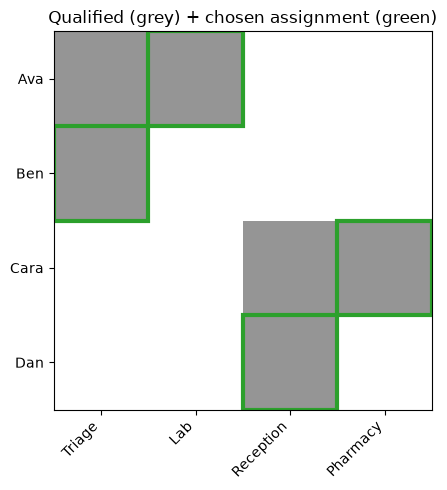

In [6]:
import numpy as np

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(np.array(qualified, dtype=float), cmap="Greys", vmin=0, vmax=2)
for p, t in assignment.items():
    ax.add_patch(
        plt.Rectangle((t - 0.5, p - 0.5), 1, 1, fill=False, edgecolor="tab:green", lw=3)
    )
ax.set_xticks(range(len(tasks)))
ax.set_xticklabels(tasks, rotation=45, ha="right")
ax.set_yticks(range(len(people)))
ax.set_yticklabels(people)
ax.set_title("Qualified (grey) + chosen assignment (green)")
fig.tight_layout()
save_figure("01_assignment_grid", fig)
plt.show()

## The mental model
Describe the **what** (the rules), let the solver find the **how** (the search). Every notebook that follows is this same move on a bigger problem.